## 1. Import libraries

In [13]:
# Import pandas to work with tables and CSV files
import pandas as pd

# Import numpy for basic mathematical calculations
import numpy as np

# Import matplotlib and seaborn to make graphs
import matplotlib.pyplot as plt
import seaborn as sns

# Split data into training, validation and testing parts
from sklearn.model_selection import train_test_split

# Import four simple regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Import metrics to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make graphs look clean
sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset
Read the CSV file and look at the first five rows.

In [14]:
# Read the dataset
df = pd.read_csv("DATASET.csv")

# Show first five rows
display(df.head())

# Show number of rows and columns
print("Dataset shape:", df.shape)

# Show column names and data types
df.info()

,record_id,attendance_pct,study_hours_week,assignment_avg,quiz_avg,sleep_hours,prior_score,study_mode,course_track,final_score,final_grade_letter,random_noise_feature
0,R1200001,43.910797,84.0,346.343508,18.384326,19.0,26.781092,West,Standard,64.539,C,-0.67988
1,R1200002,48.126544,135.0,443.501088,16.427986,11.0,26.607711,West,Compact,70.237,B,-0.99563
2,R1200003,73.977324,52.0,NaN,27.055008,14.0,47.508227,South,Standard,100.000,A,0.36948
3,R1200004,14.488324,94.0,364.866963,17.401085,10.0,25.455147,North,Compact,63.684,C,-1.06938
4,R1200005,11.810253,113.0,501.124894,23.449109,7.0,24.537191,South,Compact,65.608,C,-0.31448


Dataset shape: (708, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   record_id             708 non-null    object 
 1   attendance_pct        684 non-null    float64
 2   study_hours_week      683 non-null    float64
 3   assignment_avg        684 non-null    float64
 4   quiz_avg              683 non-null    float64
 5   sleep_hours           683 non-null    float64
 6   prior_score           684 non-null    float64
 7   study_mode            684 non-null    object 
 8   course_track          682 non-null    object 
 9   final_score           708 non-null    float64
 10  final_grade_letter    708 non-null    object 
 11  random_noise_feature  684 non-null    float64
dtypes: float64(8), object(4)
memory usage: 66.5+ KB


## 3. Check missing values and duplicate rows
This helps us understand the quality of the dataset before training.

In [15]:
# Count missing values in every column
print("Missing values:")
display(df.isnull().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Missing values:


record_id                0
attendance_pct          24
study_hours_week        25
assignment_avg          24
quiz_avg                25
sleep_hours             25
prior_score             24
study_mode              24
course_track            26
final_score              0
final_grade_letter       0
random_noise_feature    24
dtype: int64

Duplicate rows: 8
Shape after removing duplicates: (700, 12)


## 4. Select features and target
The target is the score we want to predict. The other selected columns are the input features.

In [16]:
# Columns used as input for prediction
features = [
    "attendance_pct",
    "study_hours_week",
    "assignment_avg",
    "quiz_avg",
    "sleep_hours",
    "prior_score",
    "study_mode",
    "course_track"
]

# Column we want to predict
target = "final_score"

# Check that all required columns are present
required_columns = features + [target]

for column in required_columns:
    if column not in df.columns:
        raise ValueError("Column not found in dataset: " + column)

# Keep only the columns needed for this project
df = df[required_columns].copy()

# Convert numeric columns to numbers
numeric_columns = [
    "attendance_pct",
    "study_hours_week",
    "assignment_avg",
    "quiz_avg",
    "sleep_hours",
    "prior_score",
    "final_score"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows where the final score is missing
df = df.dropna(subset=["final_score"])

print("Data ready for analysis:", df.shape)
display(df.head())

Data ready for analysis: (700, 9)


,attendance_pct,study_hours_week,assignment_avg,quiz_avg,sleep_hours,prior_score,study_mode,course_track,final_score
0,43.910797,84.0,346.343508,18.384326,19.0,26.781092,West,Standard,64.539
1,48.126544,135.0,443.501088,16.427986,11.0,26.607711,West,Compact,70.237
2,73.977324,52.0,NaN,27.055008,14.0,47.508227,South,Standard,100.000
3,14.488324,94.0,364.866963,17.401085,10.0,25.455147,North,Compact,63.684
4,11.810253,113.0,501.124894,23.449109,7.0,24.537191,South,Compact,65.608




**Why we do it:**
- Keeping only the selected columns means record_id (just an ID), final_grade_letter (made from the final score, so it would leak the answer) and random_noise_feature (no real meaning) are not used. This protects the model from target leakage and noise.
- A model cannot learn from a student whose final score is unknown, and we should never guess the target value, so those rows are removed.


## 5. Basic data cleaning
We replace impossible values with missing values. We will fill missing values after splitting the data, using information from the training data only.

In [17]:
# Attendance should be between 0 and 100
df.loc[df["attendance_pct"] < 0, "attendance_pct"] = np.nan
df.loc[df["attendance_pct"] > 100, "attendance_pct"] = np.nan

# Study hours per week cannot be negative or greater than 168
df.loc[df["study_hours_week"] < 0, "study_hours_week"] = np.nan
df.loc[df["study_hours_week"] > 168, "study_hours_week"] = np.nan

# These measurements should not be negative
for column in ["assignment_avg", "quiz_avg", "sleep_hours", "prior_score"]:
    df.loc[df[column] < 0, column] = np.nan

# Remove extra spaces and make category text lowercase
for column in ["study_mode", "course_track"]:
    df[column] = df[column].astype("string").str.strip().str.lower()

print("Cleaning completed.")
display(df.isnull().sum())

Cleaning completed.


attendance_pct      30
study_hours_week    49
assignment_avg      27
quiz_avg            29
sleep_hours         25
prior_score         26
study_mode          24
course_track        24
final_score          0
dtype: int64


- Replaces impossible values with missing values (NaN): attendance below 0 or above 100, study hours below 0 or above 168 (hours in a week), and negative assignment, quiz, sleep and prior scores.
- For study_mode and course_track, removes extra spaces and makes the text lowercase.
- Prints the missing values per column.

**Why we do it:** Values such as attendance 130% or negative marks are data-entry mistakes. If we left them, they would mislead the model. We do not delete the whole row, because the other columns of that student are still useful. Making text lowercase and removing spaces ensures that "Online", "online " and "ONLINE" are treated as one group.

**Conclusion :** The missing-value counts are now equal to or higher than before, and the extra missing values are the impossible values we just removed. These gaps are filled later using training data only, to avoid leakage.

## 6. Explore the data
First, view basic statistics and the distribution of final scores.

,attendance_pct,study_hours_week,assignment_avg,quiz_avg,sleep_hours,prior_score,final_score
count,670.000000,651.000000,673.000000,671.000000,675.000000,674.000000,700.000000
mean,49.961442,98.342550,503.719955,19.882033,10.234963,30.807387,80.382947
std,14.453038,33.435187,172.892873,6.890959,3.374298,11.085218,10.447551
min,4.565000,0.000000,82.530478,0.000000,1.000000,0.000000,46.486000
25%,40.594273,78.000000,393.612521,15.085317,8.000000,24.052253,72.792500
50%,50.411451,101.000000,500.327947,19.998309,10.000000,30.265048,80.667000
75%,59.519534,122.500000,609.373711,24.643844,12.000000,37.177011,87.402500
max,99.718532,167.000000,1565.192338,55.573791,33.840953,101.362054,100.000000


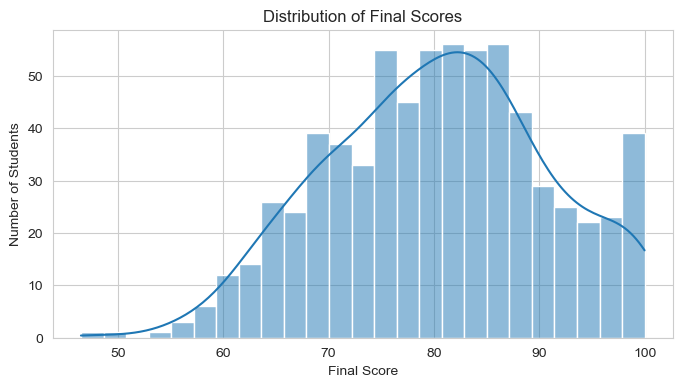

In [18]:
# Show statistics such as mean, minimum and maximum
display(df.describe())

# Plot the distribution of final scores
plt.figure(figsize=(8, 4))
sns.histplot(df["final_score"], bins=25, kde=True)
plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.show()

## 7. Explore relationships
These graphs help us see how numerical features are related to the final score.

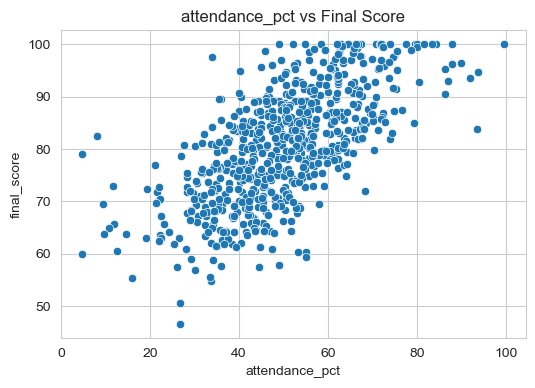

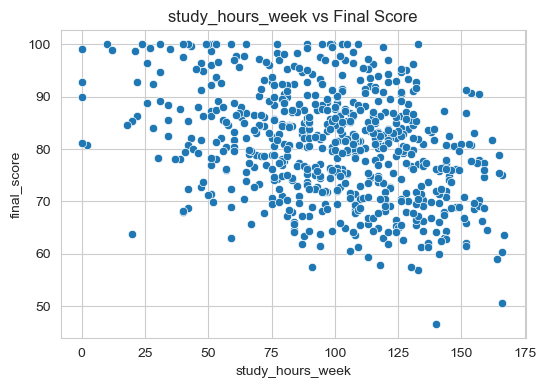

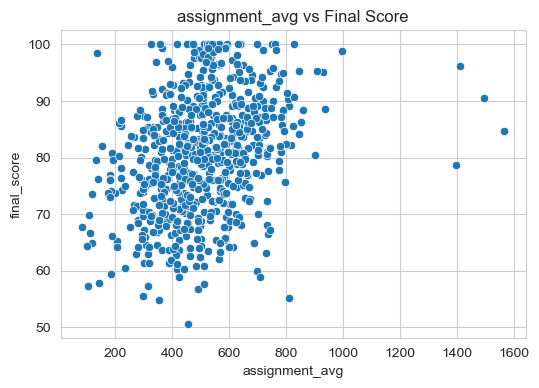

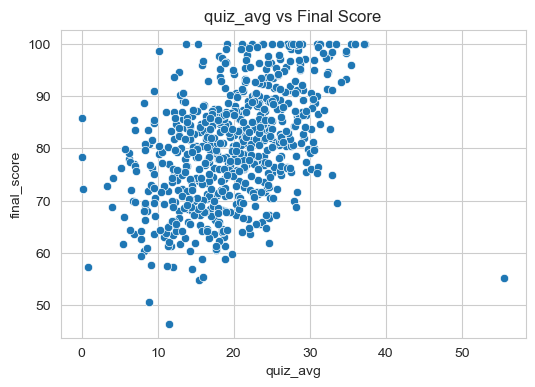

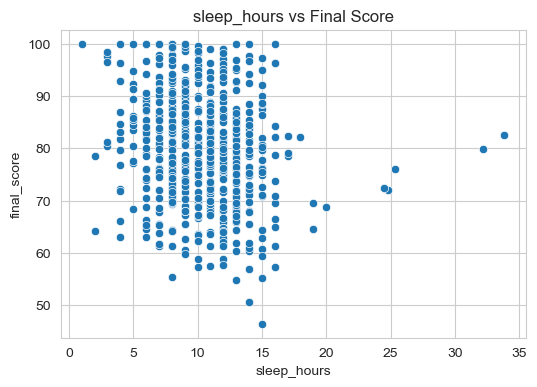

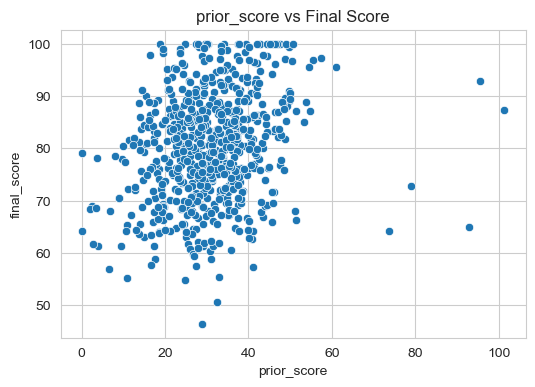

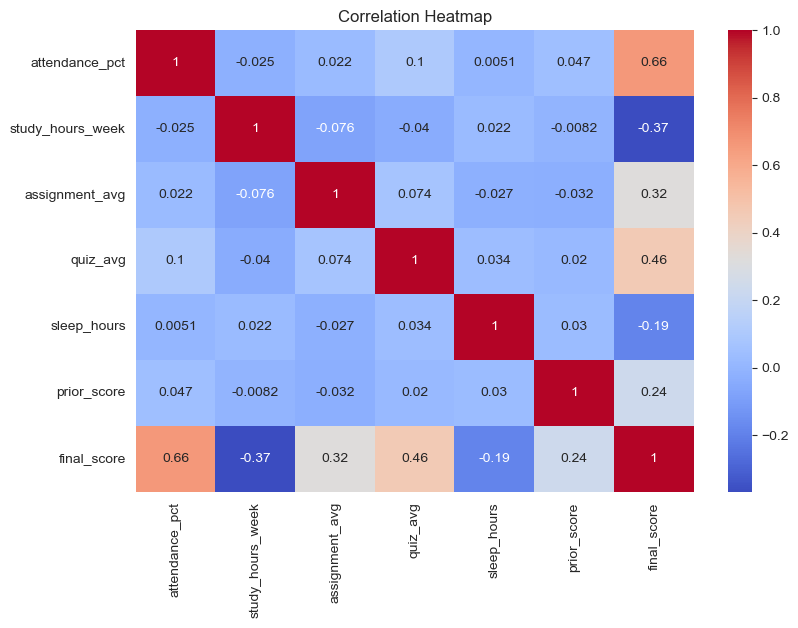

In [19]:
# Compare each numerical feature with the final score
for column in [
    "attendance_pct",
    "study_hours_week",
    "assignment_avg",
    "quiz_avg",
    "sleep_hours",
    "prior_score"
]:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=column, y="final_score")
    plt.title(column + " vs Final Score")
    plt.show()

# Show correlations between numerical columns
plt.figure(figsize=(9, 6))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()



**Why we do it:** To find which features are related to the final score. Correlation is a number from -1 to +1: near +1 means the score rises when the feature rises, near -1 means the score falls when the feature rises, and near 0 means no straight-line relationship.

**Conclusion:**
- Dots that go up from left to right show a positive relationship. A flat cloud shows no relationship.
- In the heatmap, look at the `final_score` row or column. The features with the largest values (dark red or dark blue) are the strongest predictors; values near 0 are weak predictors.
- Two features with a very high correlation with each other carry similar information.
- This is only a relationship, not proof that one thing causes the other.

## 8. Split the data
We create three parts: training data to teach models, validation data to compare models, and test data for the final check.

In [20]:
# Separate input columns (X) and target column (y)
X = df[features].copy()
y = df[target].copy()

# First, keep 15% data aside for final testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Split the remaining data into training and validation parts
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Testing rows:", len(X_test))

Training rows: 489
Validation rows: 106
Testing rows: 105




Random_state=42 makes the split the same every time.

**Why we do it:**
- **Training data** is used to teach the models.
- **Validation data** is used to compare the models and choose the best one.
- **Test data** is used only once at the end, as the final exam. The model never sees it during selection, so the result is honest.

We split **before** filling missing values so that no information from the validation or test data leaks into the training process.



## 9. Fill missing values and convert categories into numbers
Machine learning models need numerical input. We use the training data's median for missing numbers and the most common value for missing categories.

In [21]:
# Make copies so the original split data stays unchanged
X_train = X_train.copy()
X_valid = X_valid.copy()
X_test = X_test.copy()

# Fill missing numerical values using training medians
number_columns = X_train.select_dtypes(include="number").columns

for column in number_columns:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_valid[column] = X_valid[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

# Fill missing category values using the most common training value
category_columns = ["study_mode", "course_track"]

for column in category_columns:
    most_common_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(most_common_value)
    X_valid[column] = X_valid[column].fillna(most_common_value)
    X_test[column] = X_test[column].fillna(most_common_value)

# Convert text categories into separate 0/1 columns
X_train = pd.get_dummies(X_train, columns=category_columns)
X_valid = pd.get_dummies(X_valid, columns=category_columns)
X_test = pd.get_dummies(X_test, columns=category_columns)

# Make sure all three datasets have the same input columns
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Data is now ready for machine learning.")
print("Training data shape:", X_train.shape)

Data is now ready for machine learning.
Training data shape: (489, 13)




**Why we do it:**

- The median is not affected by extreme values. The same training median is used for the validation and test data, so nothing is learned from them (no leakage).
- The same columns in the same order are needed, otherwise the model cannot read the validation and test data.
- Scaling is not used because Linear Regression does not need it for this comparison and tree models do not depend on feature size.



## 10. Train and compare four models
Each model learns from the training data. We compare their validation RMSE values. A lower RMSE means smaller prediction errors.

In [22]:
# Create the four models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# This list will store model results
results = []

# Train and check each model one by one
for model_name, model in models.items():

    print("Training:", model_name)

    # Train the model
    model.fit(X_train, y_train)

    # Predict scores for validation data
    valid_predictions = model.predict(X_valid)

    # Calculate errors
    mae = mean_absolute_error(y_valid, valid_predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))
    r2 = r2_score(y_valid, valid_predictions)

    # Save the results
    results.append({
        "Model": model_name,
        "Validation MAE": mae,
        "Validation RMSE": rmse,
        "Validation R2": r2
    })

# Show models from lowest RMSE to highest RMSE
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Validation RMSE")
display(results_df.round(3))

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting


,Model,Validation MAE,Validation RMSE,Validation R2
0,Linear Regression,3.126,4.492,0.834
3,Gradient Boosting,3.553,4.537,0.831
2,Random Forest,4.269,5.402,0.760
1,Decision Tree,6.636,8.281,0.437



**Why we do it:** To compare different model types fairly on the same validation data and pick the one that predicts best. The loop avoids writing the same code four times.

## 11. Select the best model
We select the model with the lowest validation RMSE. The test data is still not used for model selection.

In [23]:
# Get the name of the model with the lowest validation RMSE
best_model_name = results_df.iloc[0]["Model"]

# Get that model from our models dictionary
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Reason: it has the lowest validation RMSE.")

Best model: Linear Regression
Reason: it has the lowest validation RMSE.


**Why we do it:** The model is chosen using the **validation** data only. The test data is not touched yet, so the final test score stays an honest, unbiased check.

**Conclusion:** This is our final model. It was selected because it makes the smallest prediction errors on validation data.

## 12. Final model evaluation
Now we check the selected model on the test data. This is our final performance check.

In [24]:
# Train the selected model using training and validation data together
X_final_train = pd.concat([X_train, X_valid])
y_final_train = pd.concat([y_train, y_valid])

best_model.fit(X_final_train, y_final_train)

# Predict scores for test data
test_predictions = best_model.predict(X_test)

# Calculate final performance values
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print("Final model:", best_model_name)
print("Test MAE:", round(test_mae, 3))
print("Test RMSE:", round(test_rmse, 3))
print("Test R2:", round(test_r2, 3))

Final model: Linear Regression
Test MAE: 2.881
Test RMSE: 4.5
Test R2: 0.835



**Why we do it:** More training data usually gives a slightly better model, and the validation data is no longer needed after the model has been chosen. The test data is used here for the first and only time, to measure performance on students the model has never seen.

**Conclusion :**
- **Test MAE:** on average the prediction is wrong by this many score points.
- **Test RMSE:** the error with a bigger penalty for large mistakes. It should be close to the validation RMSE.
- **Test R²:** the share of the score differences the model explains (for example 0.80 means 80%).
- If the test scores are much worse than the validation scores, the model has overfitted.

## 13. Actual score vs predicted score
The closer the points are to the diagonal line, the closer the predictions are to the actual scores.

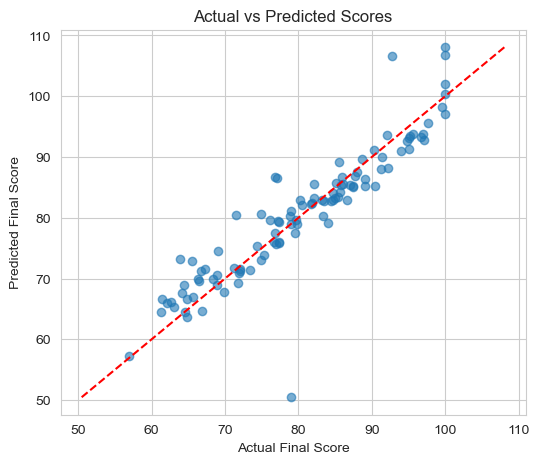

In [25]:
# Compare actual scores with model predictions
plt.figure(figsize=(6, 5))
plt.scatter(y_test, test_predictions, alpha=0.6)

# Draw a line showing perfect predictions
minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted Scores")
plt.show()




- Dots close to the red line are good predictions. A narrow band around the line means a strong model.
- Dots far from the line are large errors.
- If the dots bend away from the line at very low or very high scores, the model is less reliable for those students.

## 14. Residual analysis
A residual is the actual score minus the predicted score. This graph helps us see the model's prediction errors.

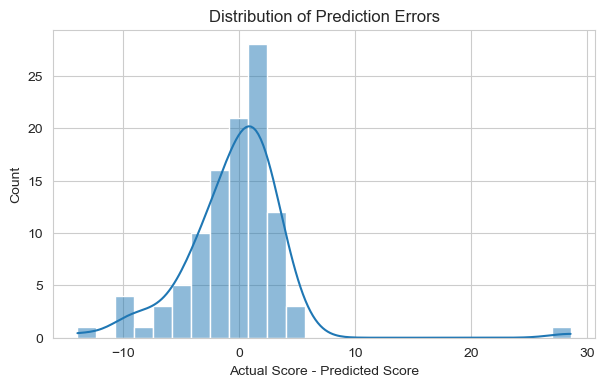

Average prediction error: -0.32


In [26]:
# Calculate prediction errors
residuals = y_test - test_predictions

# Plot the residuals
plt.figure(figsize=(7, 4))
sns.histplot(residuals, kde=True)
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Score - Predicted Score")
plt.show()

print("Average prediction error:", round(residuals.mean(), 3))




- A bell shape centred near **0** is good: the errors are balanced and there is no large pattern.
- The average error close to 0 means the model does not over-predict or under-predict on average. A positive average means it usually predicts too low; a negative average means too high.
- A long tail on one side shows a few students who are predicted badly.

## 15. Show actual and predicted values
This table lets us compare a few real scores with the model's predictions.

In [27]:
# Create a table of actual and predicted scores
prediction_table = pd.DataFrame({
    "Actual Score": y_test,
    "Predicted Score": test_predictions
})

# Add the absolute difference
prediction_table["Prediction Error"] = abs(
    prediction_table["Actual Score"] - prediction_table["Predicted Score"]
)

display(prediction_table.head(10))

,Actual Score,Predicted Score,Prediction Error
158,81.852,82.430641,0.578641
500,84.493,82.787034,1.705966
396,90.363,85.258037,5.104963
155,94.767,92.601358,2.165642
321,76.713,75.934189,0.778811
212,77.212,79.498835,2.286835
234,66.884,64.736541,2.147459
289,62.687,66.141825,3.454825
300,76.819,77.492883,0.673883
356,64.855,66.674862,1.819862


## 16. Final conclusion
The notebook has completed a basic end-to-end regression workflow: data loading, cleaning, exploration, splitting, model training, model comparison and final testing.

The best model is selected using validation RMSE. The test MAE, RMSE and R² show how well it predicts scores on data it did not train on.

